# Fall Detection Using SisFall: BiLSTM Algorithm 1

This notebook provides a practical implementation of the **BiLSTM-based fall-detection workflow** described in the supplied algorithm image:

1. Load labeled IMU recordings.
2. Select six channels: three accelerometer axes and three gyroscope axes.
3. Segment recordings into fixed-length windows.
4. Apply min–max normalization or z-score normalization.
5. Encode labels.
6. Train a bidirectional LSTM (BiLSTM).
7. Evaluate using a confusion matrix and classification metrics.
8. Save the trained model and preprocessing parameters for later inference.

> **Important:** Verify the exact column order, sensor units, sampling frequency, and label definitions against the SisFall README and the paper. Dataset file layouts can differ from assumptions in example code. This notebook intentionally keeps those settings configurable.

## Data and evaluation precautions

- Split by **participant** before creating windows to reduce leakage between overlapping windows.
- Calculate normalization parameters from the **training participants only**.
- Do not tune the model on the final test participants.
- SisFall contains simulated falls; high performance on this dataset does not establish real-world clinical reliability.
- This notebook is an experimental starting point, not a validated safety-critical fall detector.


## 1. Install and import libraries

If needed, run the install cell once in your Jupyter environment. Restart the kernel if the environment requests it.

In [13]:
# Uncomment and run if required:
%pip install numpy pandas scikit-learn matplotlib tensorflow[and-cuda]


Note: you may need to restart the kernel to use updated packages.


In [14]:
from pathlib import Path
import re
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    precision_recall_fscore_support,
    roc_auc_score,
)

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)


TensorFlow: 2.21.0
NumPy: 2.5.4


## 2. Configure the dataset and experiment

Set `DATA_DIR` to the folder containing the extracted SisFall subject directories. A common layout looks like:

```text
SisFall/
├── Readme.txt
├── SA01/
│   ├── D01_SA01_R01.txt
│   ├── F01_SA01_R01.txt
│   └── ...
├── SA02/
└── ...
```

The `D` prefix usually denotes an activity of daily living (ADL) and `F` denotes a fall. Confirm this convention in the dataset documentation.

**Channel selection:** SisFall contains recordings from multiple inertial sensors. The example below assumes the first six columns after parsing correspond to one triaxial accelerometer and one triaxial gyroscope. Confirm the actual order in the dataset README before training. If needed, update `CHANNEL_INDICES`.


In [15]:
# ---- User settings: update these for your local dataset ----
DATA_DIR = Path("SisFall")  # e.g. Path("/home/user/datasets/SisFall")

RAW_SAMPLE_RATE_HZ = 200
DOWNSAMPLE = 4  # block-average 200 Hz -> 50 Hz to shorten LSTM sequences
SAMPLE_RATE_HZ = RAW_SAMPLE_RATE_HZ // DOWNSAMPLE  # effective rate used by the model
WINDOW_SECONDS = 2.0
OVERLAP = 0.50

WINDOW_SIZE = int(SAMPLE_RATE_HZ * WINDOW_SECONDS)
STEP_SIZE = max(1, int(WINDOW_SIZE * (1.0 - OVERLAP)))

# Update these indices to match the verified SisFall column order.
CHANNEL_INDICES = [0, 1, 2, 3, 4, 5]

# Labels: 0 = ADL / non-fall, 1 = fall
ADL_PREFIX = "D"
FALL_PREFIX = "F"

print("Dataset folder exists:", DATA_DIR.exists())
print("Window size:", WINDOW_SIZE, "samples")
print("Step size:", STEP_SIZE, "samples")


Dataset folder exists: True
Window size: 100 samples
Step size: 50 samples


## 3. Discover and load recordings

The loader below handles comma-separated text files and removes fully empty columns/invalid rows. It does not automatically identify sensor columns from their names, because SisFall files commonly store numeric columns without a header.

If your files use a different delimiter or include header rows, adjust `load_recording()` before continuing.


In [16]:
def extract_subject_id(path: Path):
    # Common SisFall IDs: SA01, SA02, ..., SExx.
    for part in (path.name, path.parent.name, *path.parts[::-1]):
        match = re.search(r"\bS[AE]\d{2}\b", str(part).upper())
        if match:
            return match.group(0)
    return None


def load_recording(path: Path) -> np.ndarray:
    """Load one numeric SisFall recording and select six configured channels."""
    data = np.genfromtxt(path, delimiter=",", skip_header=1)

    if data.ndim == 1:
        data = data.reshape(1, -1)

    # Remove fully empty columns, then invalid rows.
    data = data[:, ~np.all(np.isnan(data), axis=0)]
    data = data[np.all(np.isfinite(data), axis=1)]

    if data.shape[1] <= max(CHANNEL_INDICES):
        raise ValueError(
            f"{path.name}: found {data.shape[1]} columns, "
            f"but requested indices {CHANNEL_INDICES}"
        )

    data = data[:, CHANNEL_INDICES].astype(np.float32)
    n = (len(data) // DOWNSAMPLE) * DOWNSAMPLE
    return data[:n].reshape(-1, DOWNSAMPLE, data.shape[1]).mean(axis=1)


def infer_label(path: Path):
    name = path.name.upper()
    if name.startswith(FALL_PREFIX):
        return 1
    if name.startswith(ADL_PREFIX):
        return 0
    return None


def discover_recordings(data_dir: Path):
    items = []
    for path in sorted(data_dir.rglob("*.csv")):
        if path.name.lower().startswith("readme"):
            continue
        sid = extract_subject_id(path)
        label = infer_label(path)
        if sid is None or label is None:
            continue
        items.append({"path": path, "subject": sid, "label": label})
    return items


recordings = discover_recordings(DATA_DIR)
print(f"Found {len(recordings)} candidate recordings.")
if recordings[:5]:
    display(pd.DataFrame([
        {"file": str(x["path"]), "subject": x["subject"], "label": x["label"]}
        for x in recordings[:5]
    ]))
else:
    print("No recordings found. Check DATA_DIR, folder names, and file naming.")


Found 4396 candidate recordings.


,file,subject,label
0,SisFall/SA01/D01_SA01_R01.csv,SA01,0
1,SisFall/SA01/D02_SA01_R01.csv,SA01,0
2,SisFall/SA01/D03_SA01_R01.csv,SA01,0
3,SisFall/SA01/D04_SA01_R01.csv,SA01,0
4,SisFall/SA01/D05_SA01_R01.csv,SA01,0


## 4. Split by participant before windowing

This example creates a reproducible subject-level split from the participants found in the files. It aims to keep participants separate across train, validation, and test sets.

For a research report, inspect and record the exact participant IDs assigned to each split. If a participant appears under multiple directory/file naming patterns, fix the ID extraction before training.


In [17]:
subjects = sorted({item["subject"] for item in recordings})
if len(subjects) < 3:
    raise RuntimeError(
        f"Only {len(subjects)} subjects detected. Need at least 3 for "
        "a train/validation/test split. Check the dataset path and subject parsing."
    )

rng = np.random.default_rng(SEED)
shuffled_subjects = list(subjects)
rng.shuffle(shuffled_subjects)

n = len(shuffled_subjects)
n_train = max(1, int(round(0.70 * n)))
n_val = max(1, int(round(0.15 * n)))

# Keep at least one participant for test and avoid over-allocation.
if n_train + n_val >= n:
    n_train = max(1, n - 2)
    n_val = 1

train_subjects = set(shuffled_subjects[:n_train])
val_subjects = set(shuffled_subjects[n_train:n_train + n_val])
test_subjects = set(shuffled_subjects[n_train + n_val:])

print("Train subjects:", sorted(train_subjects))
print("Validation subjects:", sorted(val_subjects))
print("Test subjects:", sorted(test_subjects))
assert not (train_subjects & val_subjects)
assert not (train_subjects & test_subjects)
assert not (val_subjects & test_subjects)


Train subjects: ['SA01', 'SA04', 'SA05', 'SA06', 'SA07', 'SA08', 'SA10', 'SA11', 'SA16', 'SA17', 'SA18', 'SA19', 'SA20', 'SA21', 'SA23', 'SE01', 'SE02', 'SE03', 'SE04', 'SE05', 'SE06', 'SE07', 'SE08', 'SE09', 'SE12', 'SE13', 'SE15']
Validation subjects: ['SA12', 'SA13', 'SA15', 'SA22', 'SE10', 'SE14']
Test subjects: ['SA02', 'SA03', 'SA09', 'SA14', 'SE11']


## 5. Segment recordings into windows

Each window receives the label of its source recording. This is a convenient first baseline, but it can introduce label noise if a fall recording contains substantial non-fall movement before or after the fall event. If event-level annotations are available, use them to label windows more precisely.


In [18]:
def segment_signal(signal: np.ndarray, label: int):
    windows = []
    labels = []
    # Falls are brief: label a window as fall only if it contains the impact
    # (peak accelerometer magnitude); other windows of fall files are dropped.
    if label == 1:
        impact_idx = int(np.argmax(np.linalg.norm(signal[:, :3], axis=1)))
    for start in range(0, len(signal) - WINDOW_SIZE + 1, STEP_SIZE):
        end = start + WINDOW_SIZE
        if label == 1 and not (start <= impact_idx < end):
            continue
        windows.append(signal[start:end])
        labels.append(label)

    if not windows:
        return (
            np.empty((0, WINDOW_SIZE, len(CHANNEL_INDICES)), dtype=np.float32),
            np.empty((0,), dtype=np.int32),
        )
    return np.stack(windows).astype(np.float32), np.asarray(labels, dtype=np.int32)


def make_split(split_subjects):
    X_parts, y_parts, metadata = [], [], []
    skipped = []

    for item in recordings:
        if item["subject"] not in split_subjects:
            continue
        try:
            signal = load_recording(item["path"])
            Xw, yw = segment_signal(signal, item["label"])
            if len(Xw) == 0:
                skipped.append(str(item["path"]))
                continue
            X_parts.append(Xw)
            y_parts.append(yw)
            metadata.extend([
                {
                    "subject": item["subject"],
                    "file": item["path"].name,
                    "label": item["label"],
                }
                for _ in range(len(yw))
            ])
        except Exception as exc:
            print(f"Skipping {item['path']}: {exc}")

    if not X_parts:
        raise RuntimeError(
            "No windows created for this split. Check parsing, channel indices, "
            "window size, and dataset contents."
        )
    return (
        np.concatenate(X_parts, axis=0),
        np.concatenate(y_parts, axis=0),
        pd.DataFrame(metadata),
    )


X_train, y_train, meta_train = make_split(train_subjects)
X_val, y_val, meta_val = make_split(val_subjects)
X_test, y_test, meta_test = make_split(test_subjects)

print("X_train:", X_train.shape, "class counts:", np.bincount(y_train, minlength=2))
print("X_val:  ", X_val.shape, "class counts:", np.bincount(y_val, minlength=2))
print("X_test: ", X_test.shape, "class counts:", np.bincount(y_test, minlength=2))

display(pd.DataFrame({
    "split": ["train", "validation", "test"],
    "windows": [len(y_train), len(y_val), len(y_test)],
    "non_fall_windows": [
        int(np.sum(y_train == 0)), int(np.sum(y_val == 0)), int(np.sum(y_test == 0))
    ],
    "fall_windows": [
        int(np.sum(y_train == 1)), int(np.sum(y_val == 1)), int(np.sum(y_test == 1))
    ],
}))


X_train: (35993, 100, 6) class counts: [33705  2288]
X_val:   (8485, 100, 6) class counts: [7885  600]
X_test:  (7363, 100, 6) class counts: [6763  600]


,split,windows,non_fall_windows,fall_windows
0,train,35993,33705,2288
1,validation,8485,7885,600
2,test,7363,6763,600


## 6. Inspect an example recording/window

Plot one window before training to check for parsing errors, unexpected scales, flat channels, or corrupted values. The displayed channel names below are placeholders until you confirm the selected column order from the dataset documentation.


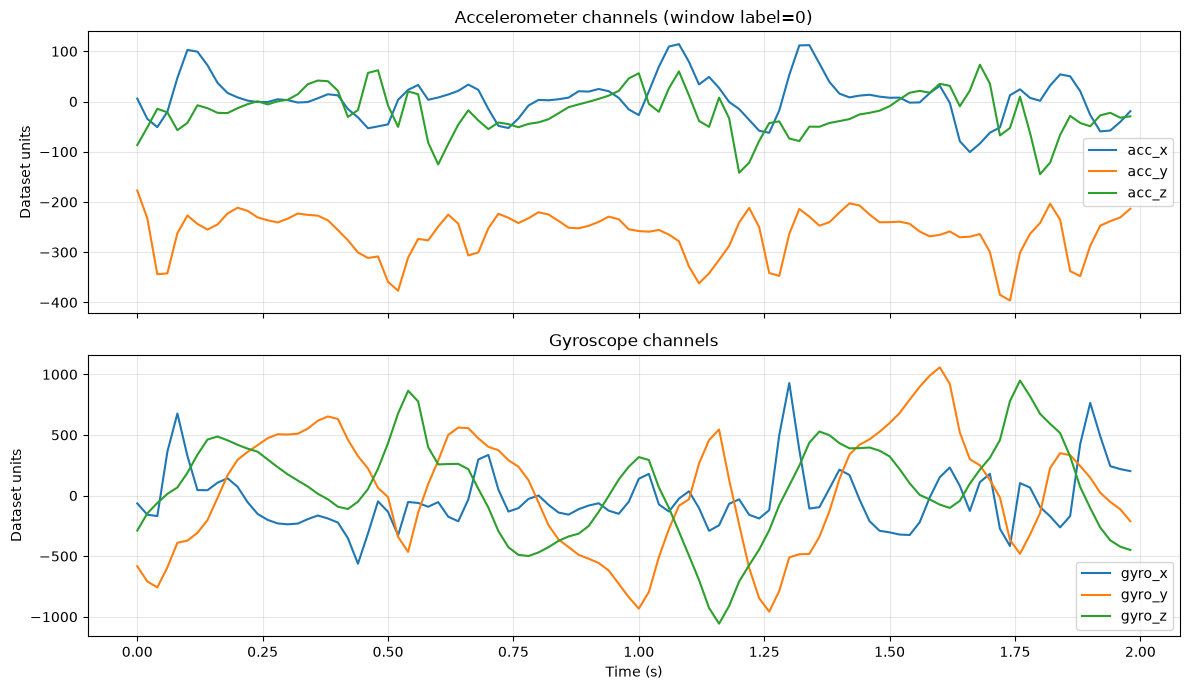

In [19]:
CHANNEL_NAMES = ["acc_x", "acc_y", "acc_z", "gyro_x", "gyro_y", "gyro_z"]

if len(X_train) > 0:
    idx = 0
    t = np.arange(WINDOW_SIZE) / SAMPLE_RATE_HZ

    fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
    for ch in range(3):
        axes[0].plot(t, X_train[idx, :, ch], label=CHANNEL_NAMES[ch])
    axes[0].set_title(f"Accelerometer channels (window label={y_train[idx]})")
    axes[0].set_ylabel("Dataset units")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    for ch in range(3, 6):
        axes[1].plot(t, X_train[idx, :, ch], label=CHANNEL_NAMES[ch])
    axes[1].set_title("Gyroscope channels")
    axes[1].set_xlabel("Time (s)")
    axes[1].set_ylabel("Dataset units")
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


## 7. Normalize the data

This notebook supports both **training-set min–max normalization** and **training-set z-score normalization**. Choose one method and keep it unchanged for validation, testing, and deployment.

- Min–max is useful when reproducing a paper that uses this transformation.
- Z-score standardization centers each channel and scales by its training standard deviation.
- Do not calculate normalization parameters from the test set.
- For transfer to a different sensor, first make sure channel order and physical units are compatible. Normalization cannot correct an incorrect axis mapping or different sensor placement.


In [20]:
NORMALIZATION = "zscore"  # choose "minmax" or "zscore"

# Calculate channel-wise parameters from training participants only.
if NORMALIZATION == "minmax":
    norm_min = X_train.min(axis=(0, 1), keepdims=True)
    norm_max = X_train.max(axis=(0, 1), keepdims=True)
    norm_scale = np.maximum(norm_max - norm_min, 1e-8)

    def normalize(X):
        return (X - norm_min) / norm_scale

    normalization_params = {"method": "minmax", "min": norm_min, "max": norm_max}

elif NORMALIZATION == "zscore":
    norm_mean = X_train.mean(axis=(0, 1), keepdims=True)
    norm_std = np.maximum(X_train.std(axis=(0, 1), keepdims=True), 1e-8)

    def normalize(X):
        return (X - norm_mean) / norm_std

    normalization_params = {"method": "zscore", "mean": norm_mean, "std": norm_std}

else:
    raise ValueError("NORMALIZATION must be 'minmax' or 'zscore'")

X_train_norm = normalize(X_train)
X_val_norm = normalize(X_val)
X_test_norm = normalize(X_test)

print("Normalization:", NORMALIZATION)
print("Normalized train min/max:", float(X_train_norm.min()), float(X_train_norm.max()))


Normalization: zscore
Normalized train min/max: -43.166481018066406 51.74031066894531


## 8. Build the BiLSTM model

The algorithm image describes two bidirectional LSTM layers followed by Dense and Dropout layers. The following is a configurable example architecture. The exact number of units and dropout rate should be adjusted to match the source paper if those values are provided there.

For binary classification, this implementation uses one sigmoid output and binary cross-entropy. This is equivalent in purpose to a two-class softmax classifier, though the output format and loss differ.


In [21]:
N_LSTM_UNITS_1 = 64
N_LSTM_UNITS_2 = 32
DROPOUT_RATE = 0.30

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(WINDOW_SIZE, len(CHANNEL_INDICES))),
    tf.keras.layers.Bidirectional(
        tf.keras.layers.LSTM(N_LSTM_UNITS_1, return_sequences=True)
    ),
    tf.keras.layers.Dropout(DROPOUT_RATE),
    tf.keras.layers.Bidirectional(
        tf.keras.layers.LSTM(N_LSTM_UNITS_2, return_sequences=False)
    ),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dropout(DROPOUT_RATE),
    tf.keras.layers.Dense(1, activation="sigmoid"),
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3, clipnorm=1.0),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
    ],
)

model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional_2 (Bidirectional) │ (None, 100, 128)       │        36,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 100, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_3 (Bidirectional) │ (None, 64)             │        41,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 79,681 (311.25 KB)

 Trainable params: 79,681 (311.25 KB)

 Non-trainable params: 0 (0.00 B)

## 9. Train the model

The class distribution may be imbalanced. This cell optionally computes class weights from the training labels only. Monitor validation metrics and avoid repeatedly tuning on the final test set.


In [22]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_train)
weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_train)
class_weight = {int(c): float(w) for c, w in zip(classes, weights)}
print("Class weights:", class_weight)

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=6, restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "best_bilstm.keras", monitor="val_loss", save_best_only=True
    ),
]

history = model.fit(
    X_train_norm,
    y_train,
    validation_data=(X_val_norm, y_val),
    epochs=40,
    batch_size=64,
    class_weight=class_weight,
    callbacks=callbacks,
    shuffle=True,
)


Class weights: {0: 0.5339415516985611, 1: 7.865603146853147}
Epoch 1/40
563/563 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - accuracy: 0.9559 - loss: 0.1281 - precision: 0.5944 - recall: 0.9663 - val_accuracy: 0.9666 - val_loss: 0.0865 - val_precision: 0.6837 - val_recall: 0.9833
Epoch 2/40
563/563 ━━━━━━━━━━━━━━━━━━━━ 8s 14ms/step - accuracy: 0.9865 - loss: 0.0552 - precision: 0.8365 - recall: 0.9795 - val_accuracy: 0.9909 - val_loss: 0.0320 - val_precision: 0.9005 - val_recall: 0.9800
Epoch 3/40
563/563 ━━━━━━━━━━━━━━━━━━━━ 8s 14ms/step - accuracy: 0.9910 - loss: 0.0372 - precision: 0.8860 - recall: 0.9851 - val_accuracy: 0.9801 - val_loss: 0.0443 - val_precision: 0.7862 - val_recall: 0.9867
Epoch 4/40
563/563 ━━━━━━━━━━━━━━━━━━━━ 8s 14ms/step - accuracy: 0.9928 - loss: 0.0309 - precision: 0.9073 - recall: 0.9882 - val_accuracy: 0.9875 - val_loss: 0.0370 - val_precision: 0.8590 - val_recall: 0.9850
Epoch 5/40
563/563 ━━━━━━━━━━━━━━━━━━━━ 8s 14ms/step - accuracy: 0.9948 - loss: 0.0246 - preci

## 10. Plot training curves

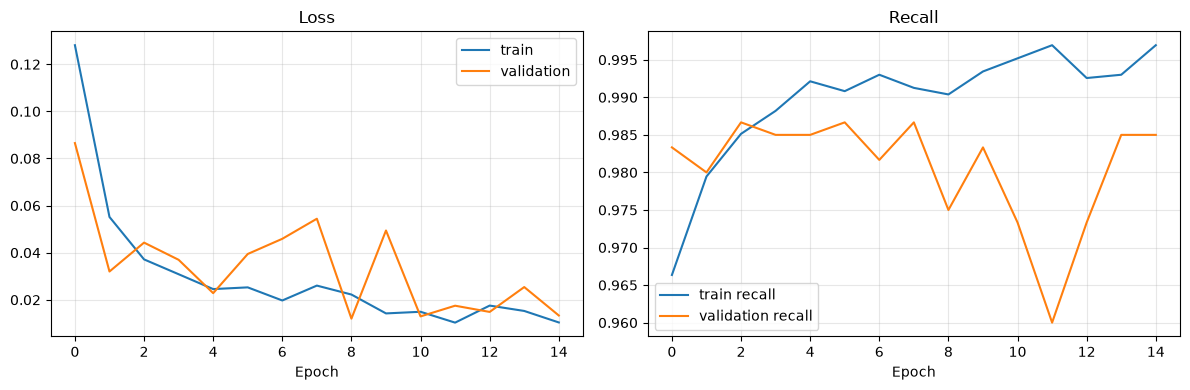

In [23]:
hist = pd.DataFrame(history.history)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hist["loss"], label="train")
axes[0].plot(hist["val_loss"], label="validation")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(hist["recall"], label="train recall")
axes[1].plot(hist["val_recall"], label="validation recall")
axes[1].set_title("Recall")
axes[1].set_xlabel("Epoch")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## 11. Evaluate on the held-out test participants

The threshold of 0.5 is a starting point, not necessarily the best operating threshold. In a real fall-detection system, select a threshold using validation data and then report the final test performance once.


Confusion matrix (rows=true, columns=predicted):
[[6747   16]
 [  17  583]]

Classification report:
                precision    recall  f1-score   support

Non-fall / ADL       1.00      1.00      1.00      6763
          Fall       0.97      0.97      0.97       600

      accuracy                           1.00      7363
     macro avg       0.99      0.98      0.99      7363
  weighted avg       1.00      1.00      1.00      7363



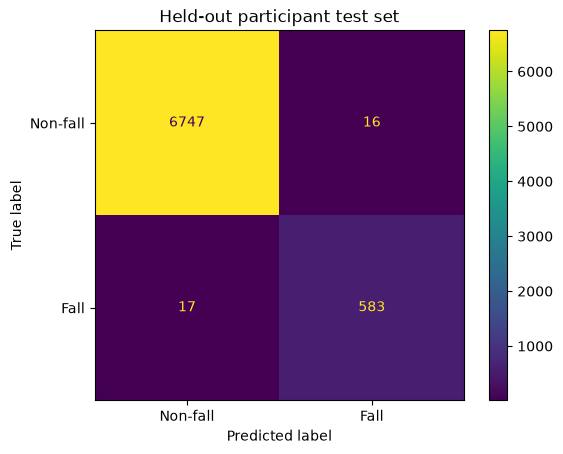

ROC AUC: 0.9973416629700823


In [24]:
test_prob = model.predict(X_test_norm, verbose=0).ravel()
THRESHOLD = 0.5
test_pred = (test_prob >= THRESHOLD).astype(np.int32)

print("Confusion matrix (rows=true, columns=predicted):")
cm = confusion_matrix(y_test, test_pred, labels=[0, 1])
print(cm)

print("\nClassification report:")
print(classification_report(
    y_test,
    test_pred,
    labels=[0, 1],
    target_names=["Non-fall / ADL", "Fall"],
    zero_division=0,
))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-fall", "Fall"]
)
disp.plot(values_format="d")
plt.title("Held-out participant test set")
plt.show()

if len(np.unique(y_test)) == 2:
    print("ROC AUC:", roc_auc_score(y_test, test_prob))
else:
    print("ROC AUC not available: test set contains only one class.")


## 12. Save model and preprocessing parameters

The normalization parameters are part of the model pipeline. Save them and reuse them at inference time. If you later use MPU6050 data, do not silently change the normalization procedure without validating the change.


In [25]:
model.save("sisfall_bilstm.keras")

save_dict = {"method": np.array(NORMALIZATION)}
for key, value in normalization_params.items():
    if key != "method":
        save_dict[key] = value
np.savez("sisfall_preprocessing.npz", **save_dict)

metadata = {
    "sample_rate_hz": SAMPLE_RATE_HZ,
    "window_seconds": WINDOW_SECONDS,
    "window_size": WINDOW_SIZE,
    "step_size": STEP_SIZE,
    "channel_indices": CHANNEL_INDICES,
    "channel_names": CHANNEL_NAMES,
    "label_mapping": {"0": "non-fall/ADL", "1": "fall"},
    "normalization": NORMALIZATION,
    "train_subjects": sorted(train_subjects),
    "validation_subjects": sorted(val_subjects),
    "test_subjects": sorted(test_subjects),
}
Path("sisfall_experiment_metadata.json").write_text(
    json.dumps(metadata, indent=2),
    encoding="utf-8"
)

print("Saved:")
print("- sisfall_bilstm.keras")
print("- sisfall_preprocessing.npz")
print("- sisfall_experiment_metadata.json")


Saved:
- sisfall_bilstm.keras
- sisfall_preprocessing.npz
- sisfall_experiment_metadata.json


## 13. Applying the saved model to MPU6050 data

For deployment, the MPU6050 pipeline must match the training pipeline:

1. Convert raw MPU6050 readings to compatible units, if necessary.
2. Map the six axes into the same channel order as training.
3. Use the same sampling frequency and window length.
4. Apply the **saved SisFall training normalization parameters**.
5. Run `model.predict()` on each window.

Example for an MPU6050 window shaped `(WINDOW_SIZE, 6)`:

```python
# Load the saved model and preprocessing parameters.
model = tf.keras.models.load_model("sisfall_bilstm.keras")
params = np.load("sisfall_preprocessing.npz")

# mpu_window must already be calibrated, correctly ordered,
# and shaped (WINDOW_SIZE, 6).
mpu_window = mpu_window.astype(np.float32)

if str(params["method"]) == "minmax":
    x_min = params["min"]
    x_max = params["max"]
    mpu_window_norm = (mpu_window - x_min) / np.maximum(x_max - x_min, 1e-8)
else:
    mean = params["mean"]
    std = params["std"]
    mpu_window_norm = (mpu_window - mean) / np.maximum(std, 1e-8)

probability = float(model.predict(mpu_window_norm[None, ...], verbose=0)[0, 0])
print("Fall probability:", probability)
```

**Do not assume transfer works just because inference runs.** Evaluate the SisFall-trained model on independent recordings from the actual MPU6050 setup. If performance is poor, investigate calibration, channel mapping, sensor placement, window labeling, and target-domain adaptation.


## 14. Research checklist

Before reporting results, verify:

- [ ] The selected SisFall channel indices and units are confirmed from the dataset documentation.
- [ ] The subject split is independent and documented.
- [ ] Normalization parameters are computed from training data only.
- [ ] No participant appears in more than one split.
- [ ] The window label corresponds as closely as possible to the event being classified.
- [ ] Class imbalance is reported and handled appropriately.
- [ ] Results include recall, precision, F1-score, confusion matrix, and false-alarm analysis where event timing permits.
- [ ] Cross-sensor transfer is evaluated using held-out MPU6050 data.
- [ ] Model size, latency, and RAM use are measured before ESP32-S3 deployment.

This notebook is a starting implementation of the workflow shown in the image. It is not guaranteed to reproduce the paper's exact numerical results unless its exact data selection, hyperparameters, and preprocessing details are matched.
